# 7 — Análise Longitudinal Periodizada

## Objetivo

Analisar a evolução do ENEM respeitando as duas estruturas históricas de desempenho presentes na base:

| Período | Estrutura de desempenho | Redação |
|---|---|---|
| **1998–2008** | `OBJETIVA` + `REDACAO` | critério do período antigo |
| **2009–2025** | `CN` + `CH` + `LC` + `MT` + `REDACAO` | critério do período novo |

### Regra metodológica central

**Não é feita uma série contínua de Redação de 1998 a 2025.** Como os critérios de pontuação da Redação mudaram, as análises longitudinais de Redação são separadas em:

- Redação 1998–2008;
- Redação 2009–2025.

Da mesma forma, `OBJETIVA` é analisada exclusivamente em 1998–2008 e as quatro áreas (`CN`, `CH`, `LC`, `MT`) exclusivamente em 2009–2025.

Isso evita interpretar como mudança longitudinal aquilo que pode decorrer da própria mudança de estrutura/critério da avaliação.

### Produtos utilizados

- `painel_municipal`
- `faixa_etaria_municipal`
- `desempenho_grupos_municipal`

### Separação dos notebooks

- **Notebook 06:** fotografia transversal de um ano.
- **Notebook 07:** evolução longitudinal periodizada.
- **Notebook 08:** análise espacial/geográfica.

O notebook não realiza tendências temporais nem mapas.

## 1. Configuração e carga

In [1]:
# ============================================================
# 1. CONFIGURAÇÃO E CARGA
# ============================================================
from _setup import *
import unicodedata
import warnings
import pandas as pd
import numpy as np
import seaborn as sns
import json
from enem_pipeline.config import (PROJECT_ROOT,DATA_DIR,METADATA_DIR,CONSUMO_DIR,UF_PROCESSAMENTO,ANO_INICIAL,ANO_FINAL)
from utils.features_names import read_allfiles
import time
from utils.eda import *
%load_ext autoreload
%autoreload 2
warnings.filterwarnings("ignore", category=FutureWarning, module="seaborn")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)

UF_PROCESSAMENTO = 'PI'

# ============================================================
# PARÂMETROS CENTRAIS
# ============================================================

ANO_INICIO_LONGITUDINAL = 1998
ANO_FIM_LONGITUDINAL = 2025

# ANO_COMPARACAO_INICIAL = 2009
# ANO_COMPARACAO_FINAL = 2025

MIN_ANOS_TENDENCIA = 5
MIN_ANOS_DISTRIBUICAO = 10



# ============================================================
# LEITURA, NORMALIZAÇÃO,PADRONIZAÇÃO 
# ============================================================

out=read_allfiles(UF_PROCESSAMENTO)
painel=out['painel']['data']
faixa=out['faixa']['data']
grupo=out['grupo']['data']

print("=" * 70)
print("EXPLORAÇÃO DA CAMADA DE CONSUMO")
print("=" * 70)
print(f"Projeto: {raiz_projeto}")
print(f"UF em processamento: {UF_PROCESSAMENTO}")
print(f"Diretório Consumo: {CONSUMO_DIR}")

print("=" * 130)
print("ARQUIVOS")
print(f"{'painel municipal':35s} → {out['painel']['caminho']}")
print(f"{'faixa etaria':35s} → {out['faixa']['caminho']}")
print(f"{'desempenho grupo':35s} → {out['faixa']['caminho']}")
print("=" * 130)

print(f"Painel : {painel.shape[0]:,} linhas × "
      f"{painel.shape[1]} colunas")
print(f"Faixa  : {faixa.shape[0]:,} linhas × "
    f"{faixa.shape[1]} colunas")
print(f"Grupo  : {grupo.shape[0]:,} linhas × "
    f"{grupo.shape[1]} colunas")



# ============================================================
# PERÍODO DISPONÍVEL PARA ANÁLISES POR GRUPOS
# ============================================================

anos_grupo = (pd.to_numeric(grupo["ano"],errors="coerce").dropna().astype(int).unique())

print('>>',anos_grupo)

ANO_FIM_GRUPOS = (
    min(ANO_FIM_LONGITUDINAL, int(anos_grupo.max()))
    if len(anos_grupo) > 0
    else ANO_FIM_LONGITUDINAL)

print(
    f"Período longitudinal: "
    f"{ANO_INICIO_LONGITUDINAL}–{ANO_FIM_LONGITUDINAL}")

print(
    f"Período disponível para grupos: "
    f"{ANO_INICIO_LONGITUDINAL}–{ANO_FIM_GRUPOS}")

EXPLORAÇÃO DA CAMADA DE CONSUMO
Projeto: /home/akel/PycharmProjects/Projeto_ENEM/notebook
UF em processamento: PI
Diretório Consumo: /home/akel/PycharmProjects/Projeto_ENEM/data/consumo
ARQUIVOS
painel municipal                    → /home/akel/PycharmProjects/Projeto_ENEM/data/consumo/uf=PI/painel_municipal.parquet
faixa etaria                        → /home/akel/PycharmProjects/Projeto_ENEM/data/consumo/uf=PI/faixa_etaria_municipal.parquet
desempenho grupo                    → /home/akel/PycharmProjects/Projeto_ENEM/data/consumo/uf=PI/faixa_etaria_municipal.parquet
Painel : 1,805 linhas × 82 colunas
Faixa  : 21,881 linhas × 7 colunas
Grupo  : 88,879 linhas × 16 colunas
>> [1998 1999 2000 2001 2002 2003 2004 2005 2006 2007 2008 2009 2010 2011
 2012 2013 2014 2015 2016 2017 2018 2019 2020 2021 2022 2023 2024 2025]
Período longitudinal: 1998–2025
Período disponível para grupos: 1998–2025


## 2. Estrutura dos dados e periodos

In [2]:
faltantes_desempenho = validar_colunas_desempenho(painel)

if faltantes_desempenho:
    raise KeyError(
        "Colunas necessárias ausentes no painel: "
        f"{faltantes_desempenho}")
# ============================================================
# 2. ESTRUTURA HISTORICA DOS PERIODOS
# ============================================================
print("=" *80)
print('2. ESTRUTURA HISTORICA DOS PERIODOS')
print("=" *80)
periodos_analiticos()

# ============================================================
# 3. COBERTURA TEMPORAL
# ============================================================
print("=" *80)
print('3. COBERTURA TEMPORAL')
print("=" *80)
ANO_FIM_GRUPOS_ANTIGO,ANO_FIM_GRUPOS_NOVO=cobertura_temporal(painel,grupo)


# ============================================================
# 4. VARIAÇÃO MUNICIPAL POR PERÍODO
# ============================================================
print("=" *80)
print('4. VARIAÇÃO MUNICIPAL POR PERÍODO')
print("=" *80)

variacao_antigo = calcular_variacao_municipal(painel,PERIODO_ANTIGO,DISCIPLINAS_ANTIGO)

variacao_novo = calcular_variacao_municipal(painel,PERIODO_NOVO,DISCIPLINAS_NOVO)

variacao_municipal_periodizada = pd.concat([variacao_antigo,variacao_novo,],ignore_index=True,)

display(variacao_municipal_periodizada.sort_values(["periodo","disciplina","delta"],ascending=[True, True, False]).head(5))

# ============================================================
# 5. TENDÊNCIA MUNICIPAL POR PERÍODO
# ============================================================
MIN_ANOS_TENDENCIA = 5


tendencia_antigo = calcular_tendencias_municipais(
    painel,
    PERIODO_ANTIGO,
    DISCIPLINAS_ANTIGO,
    MIN_ANOS_TENDENCIA,
)

tendencia_novo = calcular_tendencias_municipais(
    painel,
    PERIODO_NOVO,
    DISCIPLINAS_NOVO,
    MIN_ANOS_TENDENCIA,
)

tendencia_municipal_periodizada = pd.concat(
    [
        tendencia_antigo,
        tendencia_novo,
    ],
    ignore_index=True,
)
print("=" *80)
print( '5. TENDÊNCIA MUNICIPAL POR PERÍODO')
print("=" *80)

display(tendencia_municipal_periodizada.head(20))


# ============================================================
# 6. DISTRIBUIÇÃO DAS TENDÊNCIAS MUNICIPAIS
# ============================================================
out=tend_val(tendencia_municipal_periodizada)
print("=" *80)
print( '6. DISTRIBUIÇÃO DAS TENDÊNCIAS MUNICIPAIS')
print("=" *80)
display(out['resumo_tendencias'])

2. ESTRUTURA HISTORICA DOS PERIODOS
Períodos analíticos:
 - 1998–2008: OBJETIVA
 - 2009–2025: AREAS

✓ Estrutura histórica validada com as colunas OBJETIVA e ÁREAS.
3. COBERTURA TEMPORAL
Painel: 1998–2025
Grupos — período antigo: 1998–2008
Grupos — período novo: 2009–2008

Obs.: análises por grupos utilizam somente os anos efetivamente presentes em desempenho_grupos_municipal.
4. VARIAÇÃO MUNICIPAL POR PERÍODO


,periodo,periodo_rotulo,disciplina,versao_redacao,CO_MUNICIPIO_TERRITORIO,NO_MUNICIPIO_TERRITORIO,media_inicial,media_final,delta
1,1998_2008,1998–2008,OBJETIVA,None,2211001,TERESINA,32.782653,30.051039,-2.731614
0,1998_2008,1998–2008,OBJETIVA,None,2208007,PICOS,41.300000,25.372317,-15.927683
3,1998_2008,1998–2008,REDACAO,antiga,2211001,TERESINA,36.581633,45.872923,9.291291
2,1998_2008,1998–2008,REDACAO,antiga,2208007,PICOS,60.000000,42.018634,-17.981366
95,2009_2025,2009–2025,CH,None,2211209,URUCUI,437.742000,459.726567,21.984567


5. TENDÊNCIA MUNICIPAL POR PERÍODO


,periodo,periodo_rotulo,disciplina,versao_redacao,CO_MUNICIPIO_TERRITORIO,NO_MUNICIPIO_TERRITORIO,n_anos,pct_cobertura,ano_inicial,ano_final,media_inicial,media_final,variacao_primeiro_ultimo,slope_pontos_ano,erro_padrao_slope,r2,p_valor,direcao
0,1998_2008,1998–2008,OBJETIVA,NaN,2200103,AGRICOLANDIA,7,63.636364,2001,2007,12.781579,26.190714,13.409135,4.062760,1.925276,0.471069,0.088597,positiva
1,1998_2008,1998–2008,REDACAO,antiga,2200103,AGRICOLANDIA,7,63.636364,2001,2007,18.289474,33.452381,15.162907,5.734458,3.264263,0.381657,0.139307,positiva
2,1998_2008,1998–2008,OBJETIVA,NaN,2200202,AGUA BRANCA,9,81.818182,1999,2007,17.460000,39.109381,21.649381,0.412017,1.642128,0.008913,0.809094,positiva
3,1998_2008,1998–2008,REDACAO,antiga,2200202,AGUA BRANCA,9,81.818182,1999,2007,0.000000,44.561856,44.561856,2.500166,1.916027,0.195651,0.233194,positiva
4,1998_2008,1998–2008,OBJETIVA,NaN,2200251,ALAGOINHA DO PIAUI,6,54.545455,2001,2007,33.333571,24.673088,-8.660483,-1.483960,1.645828,0.168913,0.418226,negativa
5,1998_2008,1998–2008,REDACAO,antiga,2200251,ALAGOINHA DO PIAUI,6,54.545455,2001,2007,48.035714,33.602941,-14.432773,-2.831070,2.243848,0.284679,0.275616,negativa
6,1998_2008,1998–2008,OBJETIVA,NaN,2200277,ALEGRETE DO PIAUI,7,63.636364,2001,2007,27.585862,37.823143,10.237281,1.338479,1.500160,0.137346,0.413148,positiva
7,1998_2008,1998–2008,REDACAO,antiga,2200277,ALEGRETE DO PIAUI,7,63.636364,2001,2007,44.051724,53.000000,8.948276,1.123197,2.175584,0.050610,0.627676,positiva
8,1998_2008,1998–2008,OBJETIVA,NaN,2200301,ALTO LONGA,8,72.727273,1999,2007,25.042222,31.443492,6.401270,0.861484,1.257501,0.072547,0.518871,positiva
9,1998_2008,1998–2008,REDACAO,antiga,2200301,ALTO LONGA,8,72.727273,1999,2007,31.368889,38.571429,7.202540,1.110532,1.705554,0.065998,0.539086,positiva


6. DISTRIBUIÇÃO DAS TENDÊNCIAS MUNICIPAIS


,periodo,disciplina,n_municipios,mediana_slope,media_slope,pct_slope_positivo,n_tendencias_significativas,pct_tendencias_significativas
0,1998_2008,OBJETIVA,151,0.935473,1.002663,74.172185,16,10.596026
1,1998_2008,REDACAO,151,1.065233,1.186109,70.198675,13,8.609272
2,2009_2025,CH,33,-0.547258,-0.754481,12.121212,2,6.060606
3,2009_2025,CN,33,1.203043,1.233186,100.000000,10,30.303030
4,2009_2025,LC,33,1.605839,1.711172,100.000000,26,78.787879
5,2009_2025,MT,33,2.064368,2.251830,96.969697,25,75.757576
6,2009_2025,REDACAO,33,16.103365,16.376634,100.000000,32,96.969697


## 3 Distribuição das inclinações

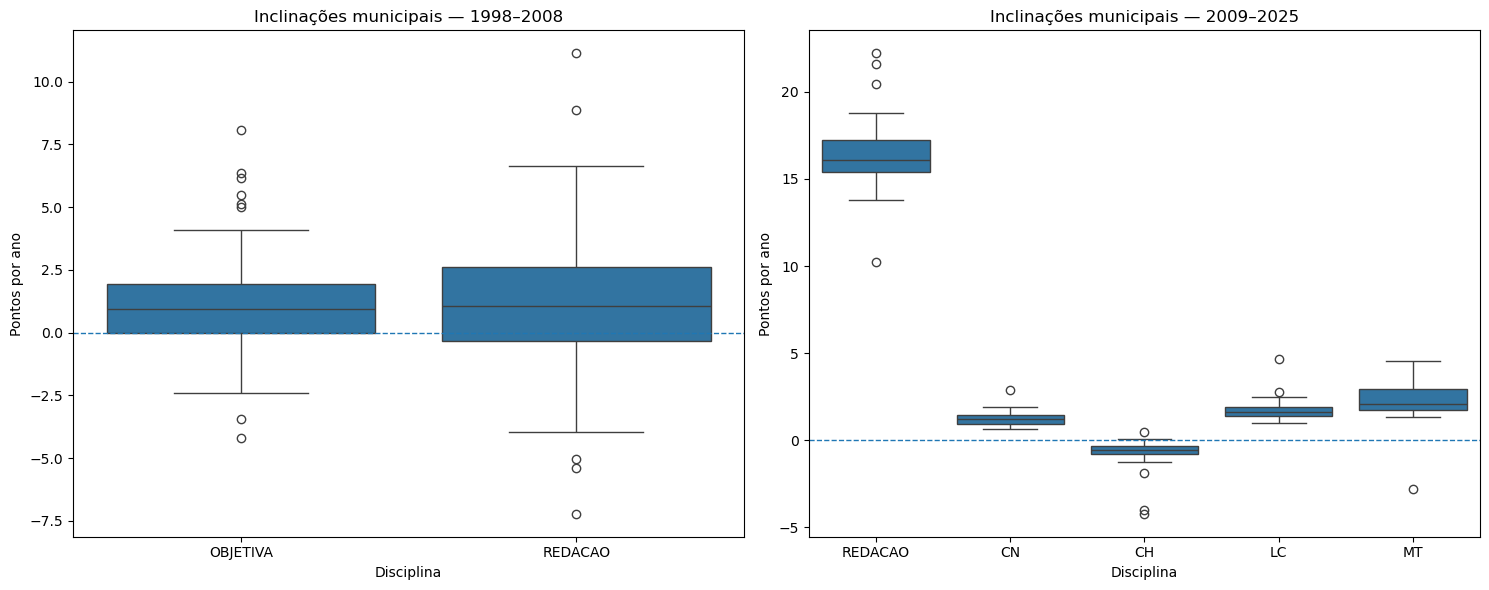

In [3]:
# ============================================================
# 3.1. BOXPLOT DAS INCLINAÇÕES POR PERÍODO
# ============================================================
tendencias_validas=out['tendencias_validas']
fig, axes = plt.subplots(1,2,figsize=(15, 6))

ordem_antigo = [ "OBJETIVA","REDACAO"]

ordem_novo = ["REDACAO","CN","CH","LC","MT"]

dados_antigo = tendencias_validas[
tendencias_validas["periodo"] == "1998_2008"]

dados_novo = tendencias_validas[
tendencias_validas["periodo"] == "2009_2025"
]

sns.boxplot(data=dados_antigo,x="disciplina",y="slope_pontos_ano",
            order=ordem_antigo,
            ax=axes[0])

axes[0].axhline(0,linestyle="--",linewidth=1)

axes[0].set_title("Inclinações municipais — 1998–2008")

axes[0].set_xlabel("Disciplina")
axes[0].set_ylabel("Pontos por ano")


sns.boxplot(data=dados_novo,x="disciplina",y="slope_pontos_ano",
            order=ordem_novo,
            ax=axes[1]
           )

axes[1].axhline(0,linestyle="--",
                linewidth=1)

axes[1].set_title("Inclinações municipais — 2009–2025")

axes[1].set_xlabel("Disciplina")
axes[1].set_ylabel("Pontos por ano")
plt.tight_layout()
plt.show()

## 4. Evolução estadual e tendência linear por período

In [4]:
out_old = calcular_tendencia_estadual(painel,PERIODO_ANTIGO,DISCIPLINAS_ANTIGO)
out_new = calcular_tendencia_estadual(painel,PERIODO_NOVO,DISCIPLINAS_NOVO)
           
dados_estaduais_antigo     =out_old['dados']
tendencia_estadual_antigo  =out_old['tendencia']
dados_estaduais_novo       =out_new['dados']
tendencia_estadual_novo    =out_new['tendencia']


tendencia_estadual_periodizada = pd.concat(
    [tendencia_estadual_antigo,tendencia_estadual_novo],ignore_index=True)

dados_tendencia_estadual = pd.concat(
    [dados_estaduais_antigo,dados_estaduais_novo],ignore_index=True)

print("Síntese estadual:")
display(tendencia_estadual_periodizada.round(3))

Síntese estadual:


,periodo,periodo_rotulo,disciplina,versao_redacao,n_anos,media_inicial,media_final,variacao_primeiro_ultimo,slope_pontos_ano,erro_padrao_slope,r2,p_valor
0,1998_2008,1998–2008,OBJETIVA,NaN,11,32.085,27.632,-4.453,-1.481,1.000,0.196,0.173
1,1998_2008,1998–2008,REDACAO,antiga,11,36.019,44.297,8.278,-0.702,1.033,0.049,0.514
2,2009_2025,2009–2025,REDACAO,nova,17,408.428,571.616,163.188,16.175,2.739,0.699,0.000
3,2009_2025,2009–2025,CN,NaN,17,480.898,482.841,1.944,1.069,0.570,0.190,0.080
4,2009_2025,2009–2025,CH,NaN,17,490.928,487.763,-3.165,-0.778,1.142,0.030,0.506
5,2009_2025,2009–2025,LC,NaN,17,482.503,510.835,28.332,1.261,0.494,0.303,0.022
6,2009_2025,2009–2025,MT,NaN,17,473.346,491.416,18.069,2.796,0.820,0.436,0.004


### 4.1 Visualização das médias estaduais

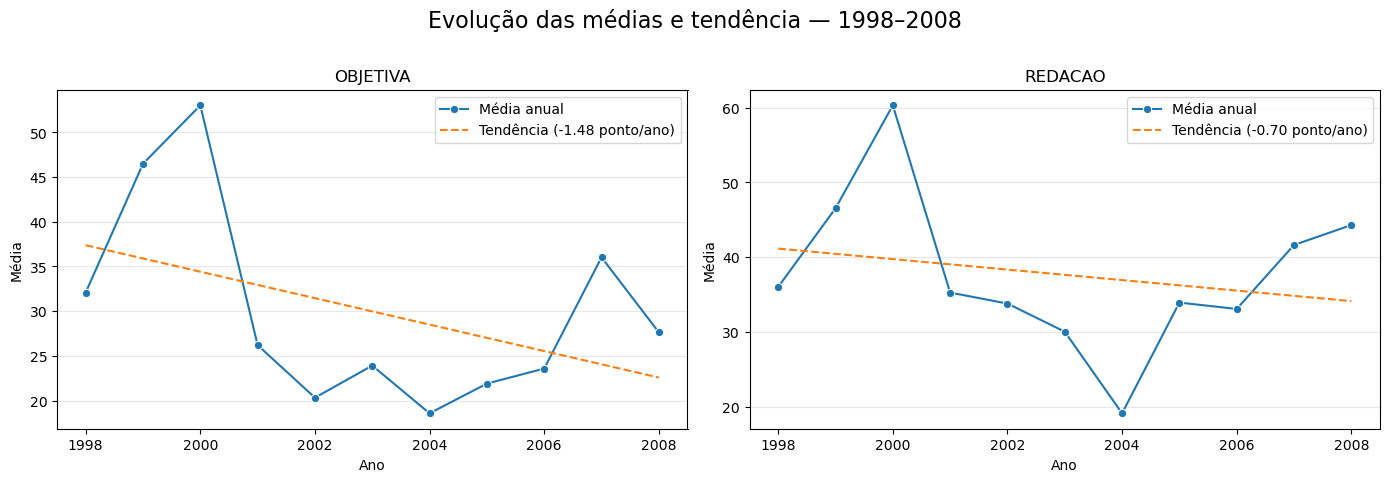

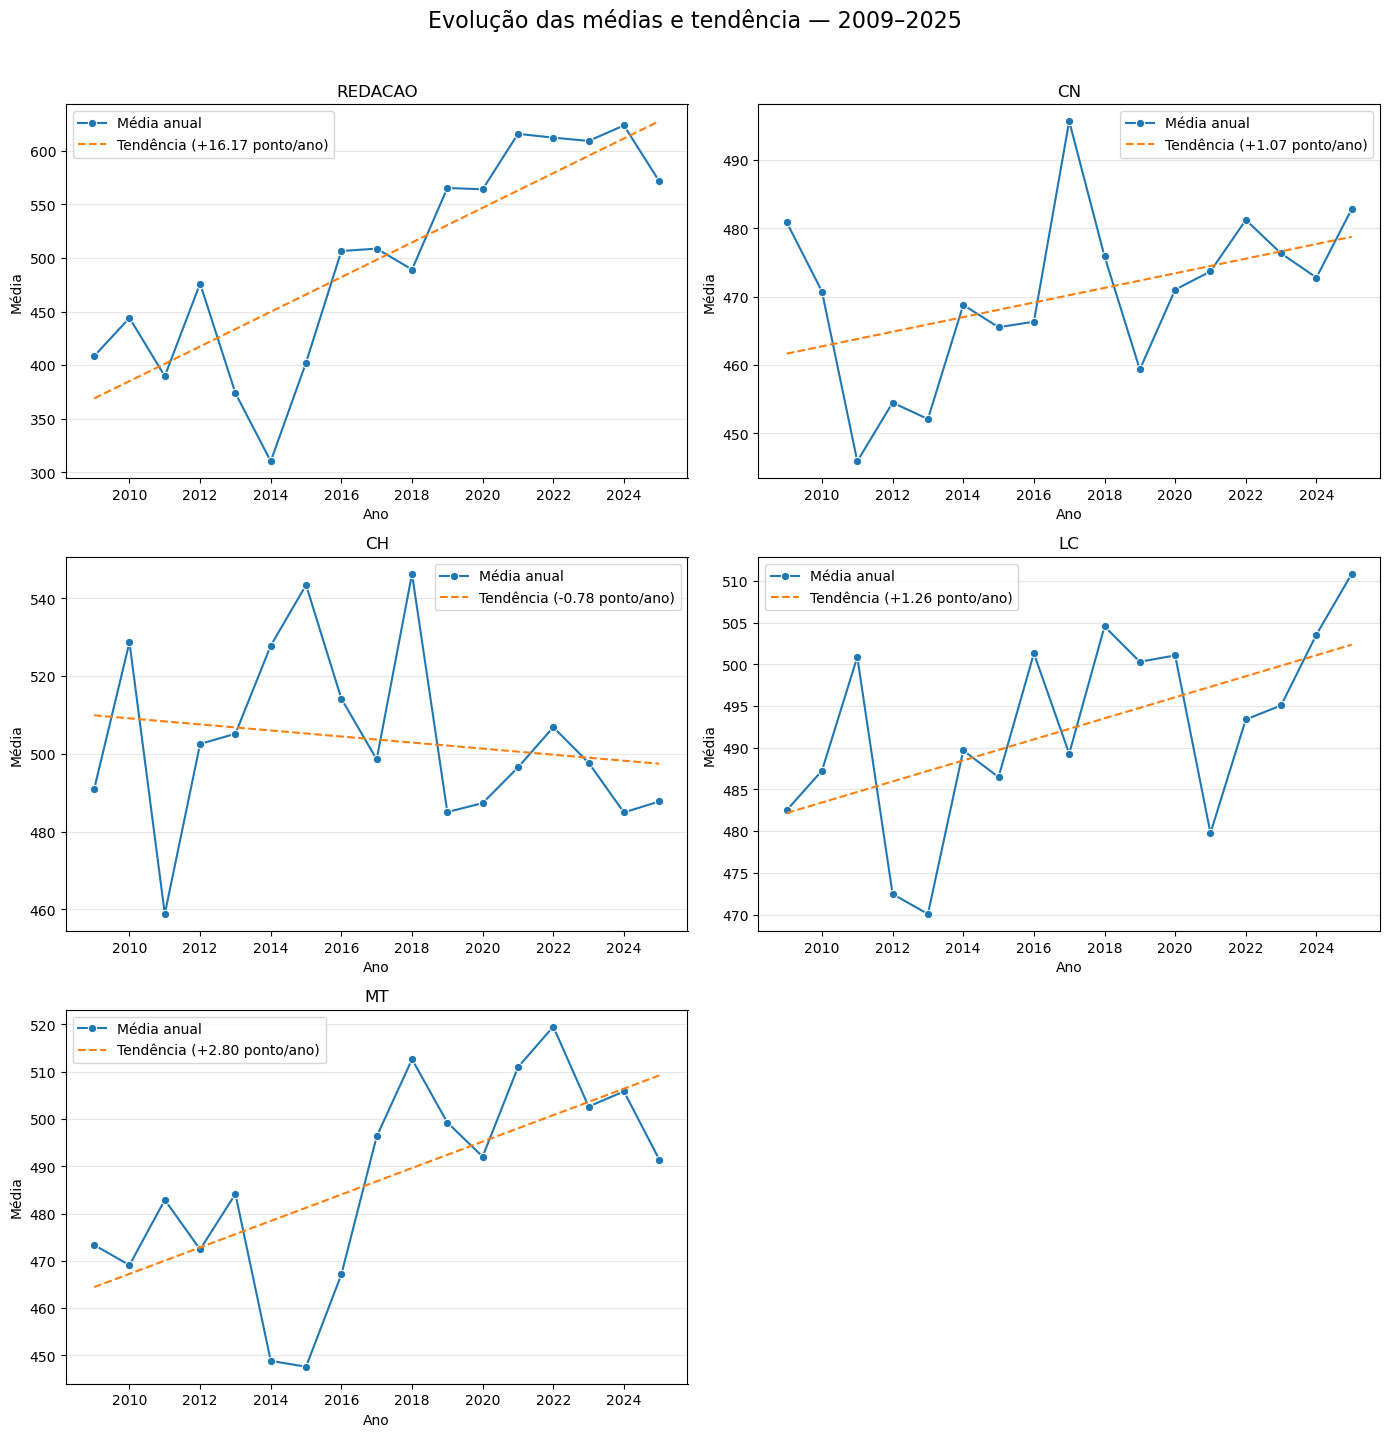

In [5]:
# ============================================================
# 4.1. VISUALIZAÇÃO DAS MÉDIAS ESTADUAIS
# ============================================================

plotar_tendencia_estadual(
    dados_estaduais_antigo,
    PERIODO_ANTIGO,
    DISCIPLINAS_ANTIGO)

plotar_tendencia_estadual(
    dados_estaduais_novo,
    PERIODO_NOVO,
    DISCIPLINAS_NOVO)

## 5. Evolução por rede escolar

In [6]:
print(f"\n# Processo iniciado em: {time.strftime('%H:%M:%S')}")
rede_escolar_anual=rede_escolar(grupo)
display(rede_escolar(grupo))


# Processo iniciado em: 08:58:56


,periodo,ano,rede,disciplina,n_validos,media
0,1998_2008,2001,PRIVADA,OBJETIVA,979,40.160848
1,1998_2008,2001,PÚBLICA,OBJETIVA,5876,23.867246
2,1998_2008,2001,PRIVADA,REDACAO,979,50.066394
3,1998_2008,2001,PÚBLICA,REDACAO,5876,32.803778
4,1998_2008,2002,PRIVADA,OBJETIVA,2573,33.410369
...,...,...,...,...,...,...
284,2009_2025,2025,PRIVADA,MT,3550,627.059296
285,2009_2025,2025,PÚBLICA,MT,26260,469.971222
286,2009_2025,2025,NAO_INFORMADA,REDACAO,58684,571.726535
287,2009_2025,2025,PRIVADA,REDACAO,3573,792.712007


### 5.1 Visualização por período

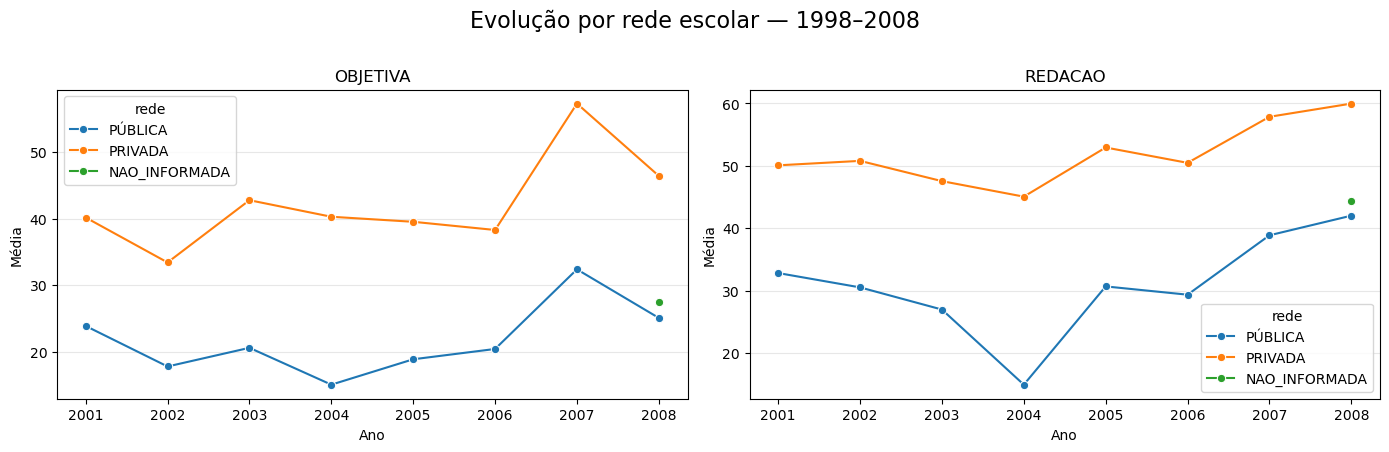

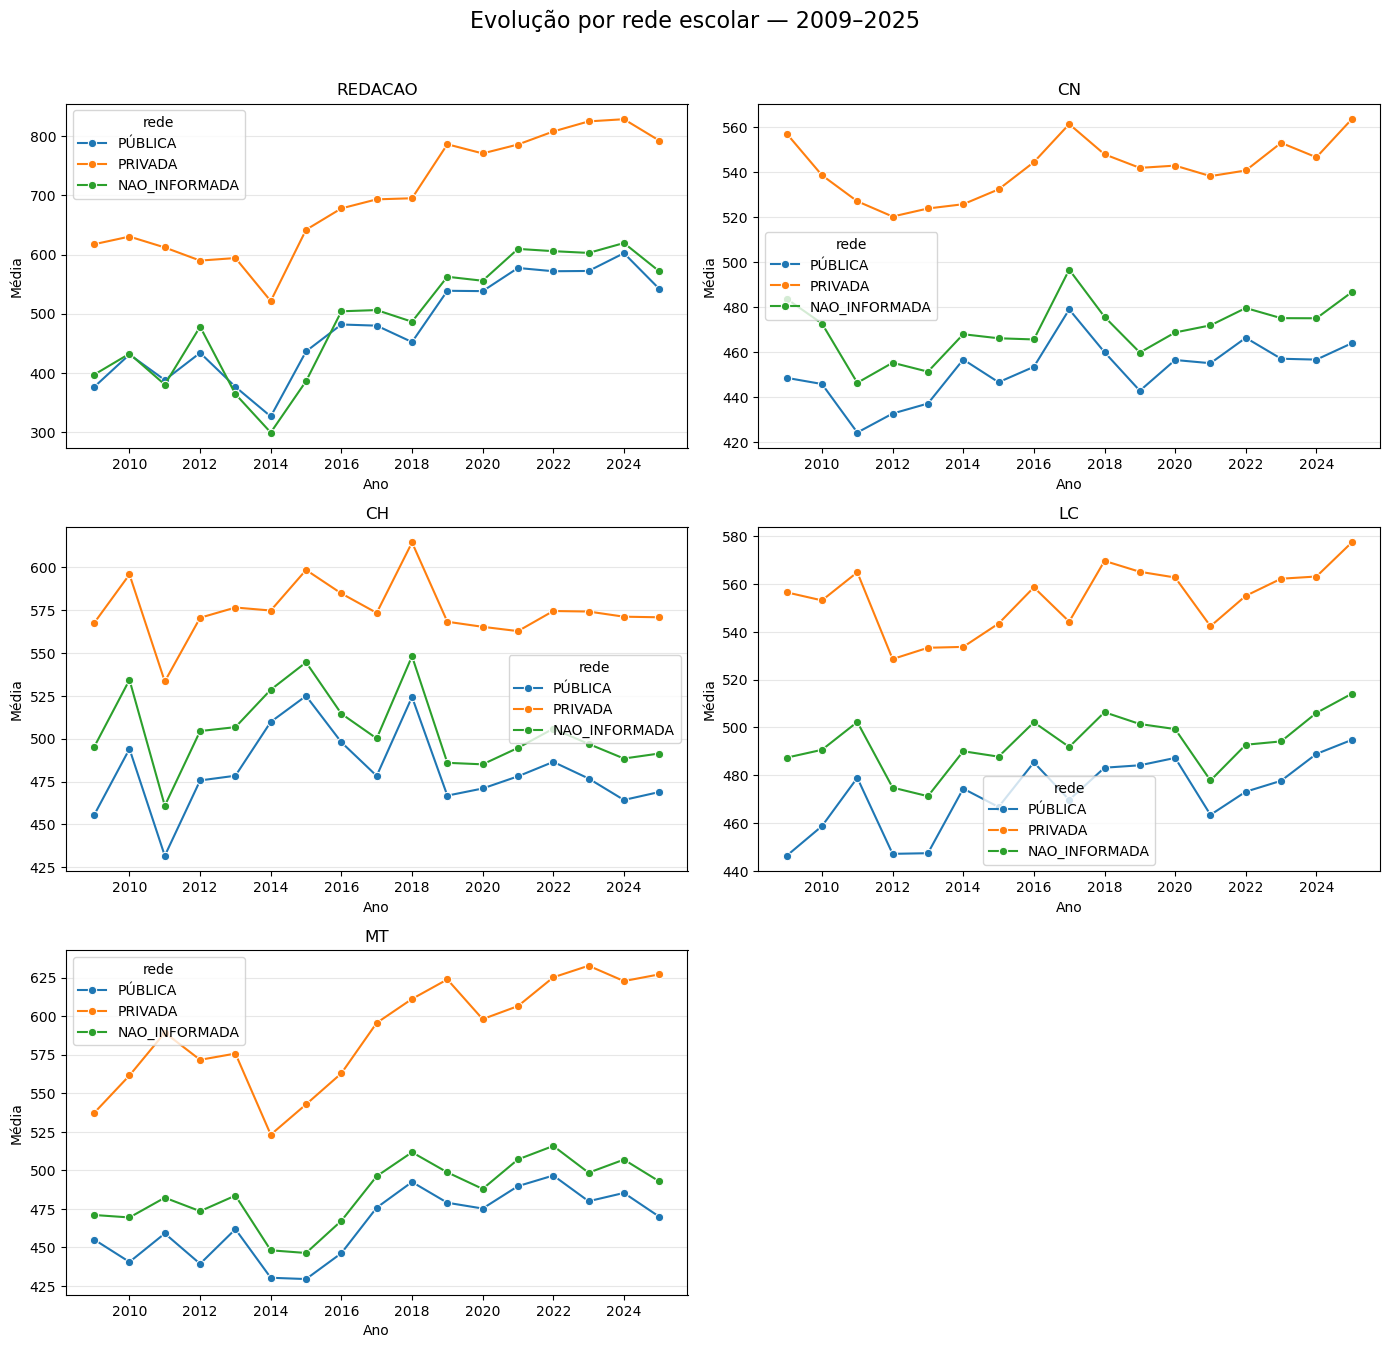

In [7]:
# ============================================================
# 5.1. VISUALIZAÇÃO — REDE ESCOLAR
# ============================================================
plotar_grupo_escola(
    rede_escolar_anual,
    "1998_2008",
    DISCIPLINAS_ANTIGO)

plotar_grupo_escola(
    rede_escolar_anual,
    "2009_2025",
    DISCIPLINAS_NOVO)

## 6. Evolução por sexo

In [8]:
# ============================================================
# 6. SEXO — EVOLUÇÃO PERIODIZADA
# ============================================================
sexo_anual=sex_period(grupo)
display(sexo_anual)

,periodo,ano,grupo,disciplina,n_validos,media
0,1998_2008,1998,FEMININO,OBJETIVA,65,33.236923
1,1998_2008,1998,MASCULINO,OBJETIVA,38,30.115789
2,1998_2008,1998,FEMININO,REDACAO,65,40.461538
3,1998_2008,1998,MASCULINO,REDACAO,38,28.421053
4,1998_2008,1999,FEMININO,OBJETIVA,595,41.456555
...,...,...,...,...,...,...
189,2009_2025,2023,MASCULINO,LC,28732,495.354998
190,2009_2025,2023,FEMININO,MT,43293,486.526429
191,2009_2025,2023,MASCULINO,MT,27755,527.689133
192,2009_2025,2023,FEMININO,REDACAO,44705,625.483950


### 6.1 Visualização por período

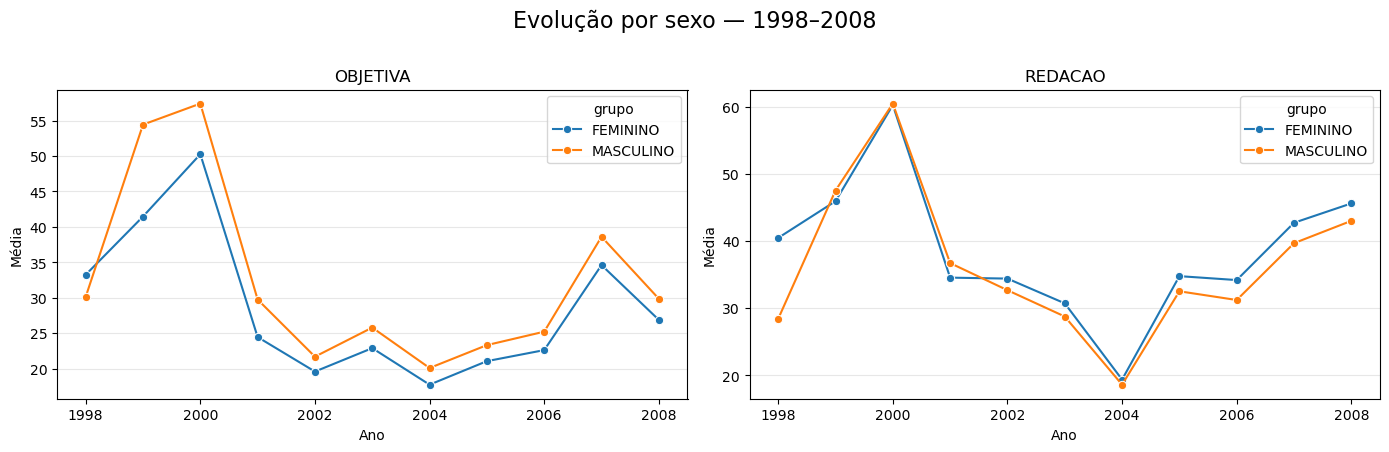

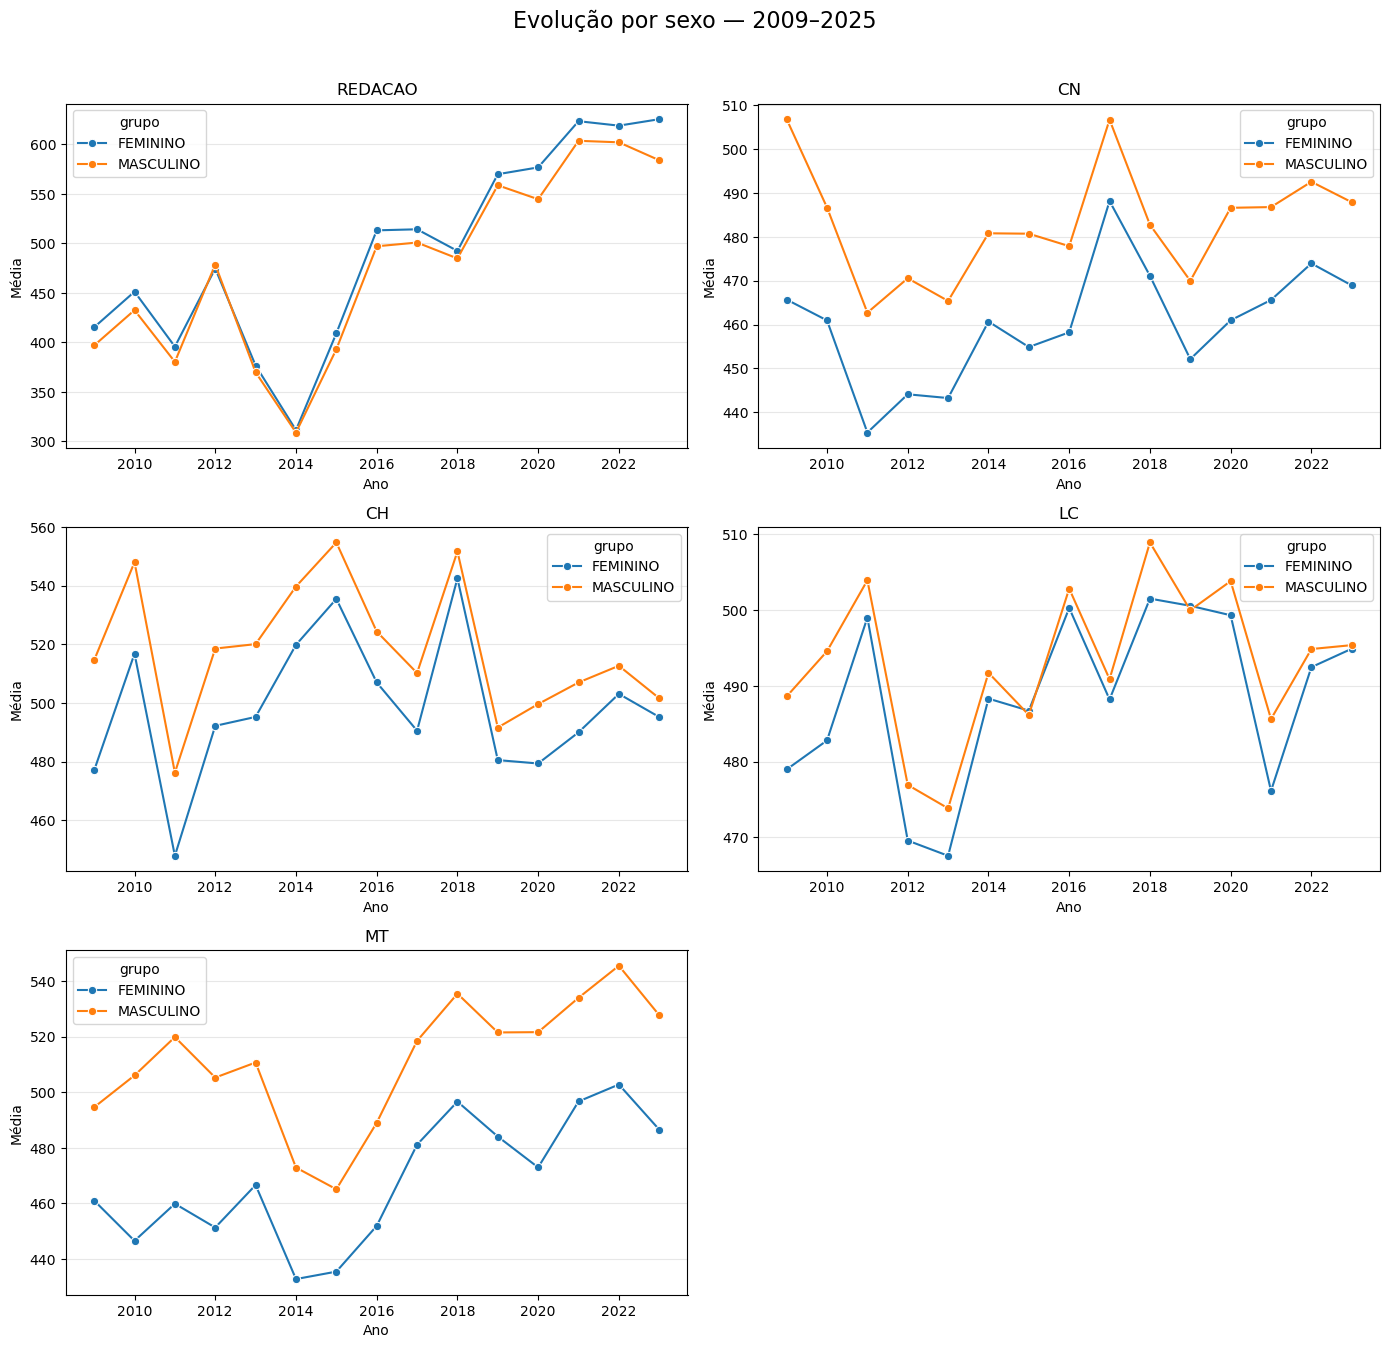

In [9]:
# ============================================================
# 6.1. VISUALIZAÇÃO — SEXO
# ============================================================
plotar_grupo_sexo(sexo_anual,"1998_2008",DISCIPLINAS_ANTIGO)

plotar_grupo_sexo(sexo_anual,"2009_2025",DISCIPLINAS_NOVO)

## 7. Evolução por faixa etária

In [10]:
# ============================================================
# 7. FAIXA ETÁRIA — EVOLUÇÃO PERIODIZADA
# ============================================================
from utils.eda import faixa_period
faixa_anual=faixa_period(grupo)
display(faixa_anual)

,periodo,ano,grupo_faixa,disciplina,n_validos,media
0,1998_2008,1998,17–20,OBJETIVA,50,44.096000
1,1998_2008,1998,21–25,OBJETIVA,21,12.623810
2,1998_2008,1998,26–40,OBJETIVA,22,15.727273
3,1998_2008,1998,<17,OBJETIVA,9,50.444444
4,1998_2008,1998,>40,OBJETIVA,1,34.900000
...,...,...,...,...,...,...
480,2009_2025,2023,17–20,REDACAO,46036,627.683986
481,2009_2025,2023,21–25,REDACAO,10188,592.202591
482,2009_2025,2023,26–40,REDACAO,6216,530.270270
483,2009_2025,2023,<17,REDACAO,9098,622.499450


### 7.1 Visualização por período

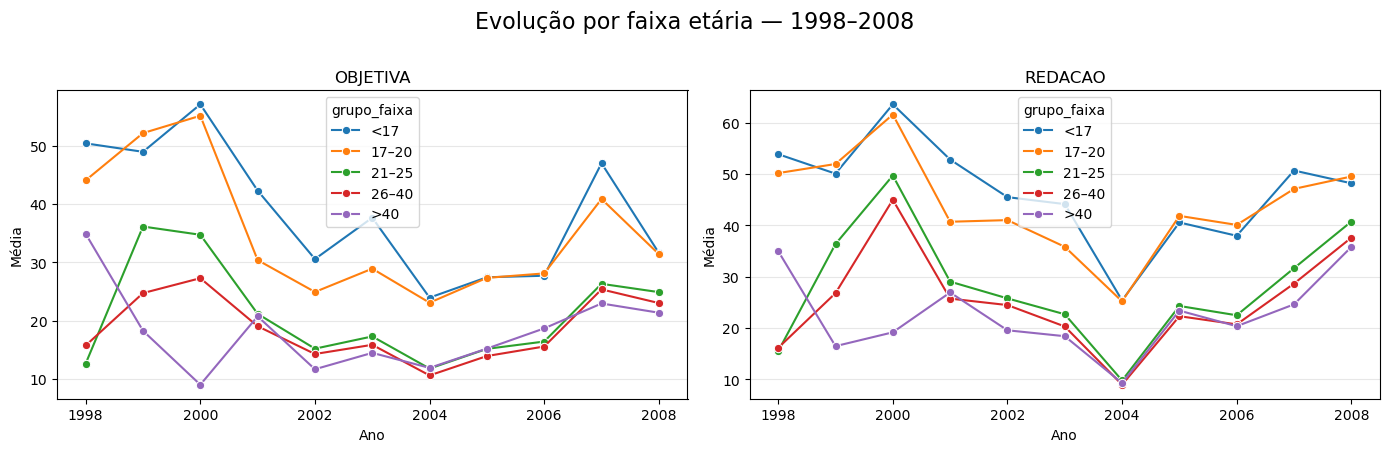

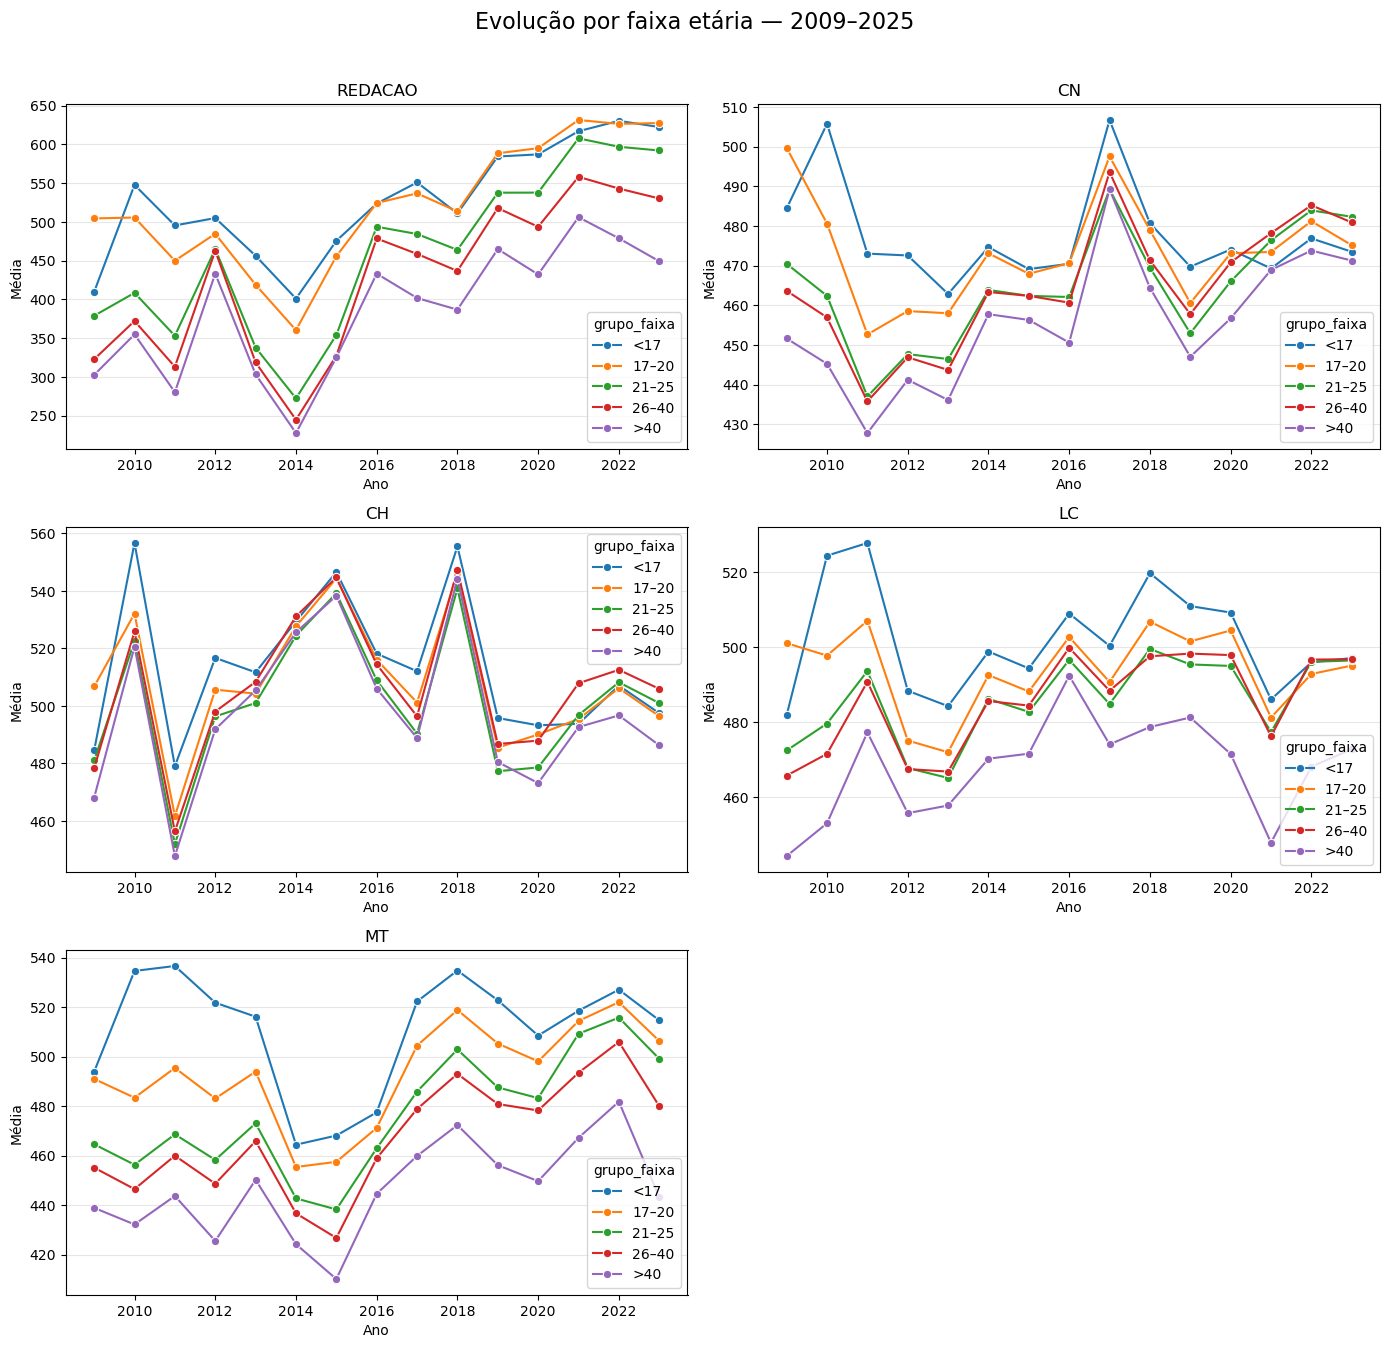

In [11]:
# ============================================================
# 7.1. VISUALIZAÇÃO — FAIXA ETÁRIA
# ============================================================

from utils.eda import plotar_grupo_faixa

plotar_grupo_faixa( faixa_anual,"1998_2008",DISCIPLINAS_ANTIGO)
plotar_grupo_faixa(faixa_anual,"2009_2025",DISCIPLINAS_NOVO)

### 7.2 Proporção dos participantes por faixa etária

In [12]:
# ============================================================
# 7.2. PROPORÇÃO DOS PARTICIPANTES POR FAIXA ETÁRIA
# ============================================================
from utils.eda import proporcao_period

proporcao_faixa_periodizada=proporcao_period(faixa)

display(proporcao_faixa_periodizada.round(2))

,periodo,grupo_faixa,n_participantes,pct_participantes
0,1998_2008,<17,3066,1.68
1,1998_2008,17–20,99567,54.70
2,1998_2008,21–25,48634,26.72
3,1998_2008,26–40,26981,14.82
4,1998_2008,>40,3768,2.07
5,2009_2025,<17,187089,8.78
6,2009_2025,17–20,981857,46.06
7,2009_2025,21–25,470421,22.07
8,2009_2025,26–40,402486,18.88
9,2009_2025,>40,89672,4.21


## 8. Estabilidade relativa da posição municipal

In [13]:
# ============================================================
# 11. ESTABILIDADE RELATIVA DA POSIÇÃO MUNICIPAL
# ============================================================

from utils.eda import calcular_estabilidade


estabilidade_1998_2008 = calcular_estabilidade(
    painel,
    1998,
    2008,
    DISCIPLINAS_ANTIGO,
    "1998_2008")

estabilidade_2009_2025 = calcular_estabilidade(
    painel,
    2009,
    2025,
    DISCIPLINAS_NOVO,
    "2009_2025")

estabilidade_posicao_periodizada = pd.concat(
    [
        estabilidade_1998_2008,
        estabilidade_2009_2025,
    ],
    ignore_index=True)

display(estabilidade_posicao_periodizada.round(4)
)

,periodo,ano_inicial,ano_final,disciplina,versao_redacao,n_municipios,spearman,p_valor
0,2009_2025,2009,2025,REDACAO,nova,31,0.6161,0.0002
1,2009_2025,2009,2025,CN,NaN,31,0.8004,0.0000
2,2009_2025,2009,2025,CH,NaN,31,0.9052,0.0000
3,2009_2025,2009,2025,LC,NaN,31,0.8730,0.0000
4,2009_2025,2009,2025,MT,NaN,31,0.6145,0.0002


### 8.1 Visualização

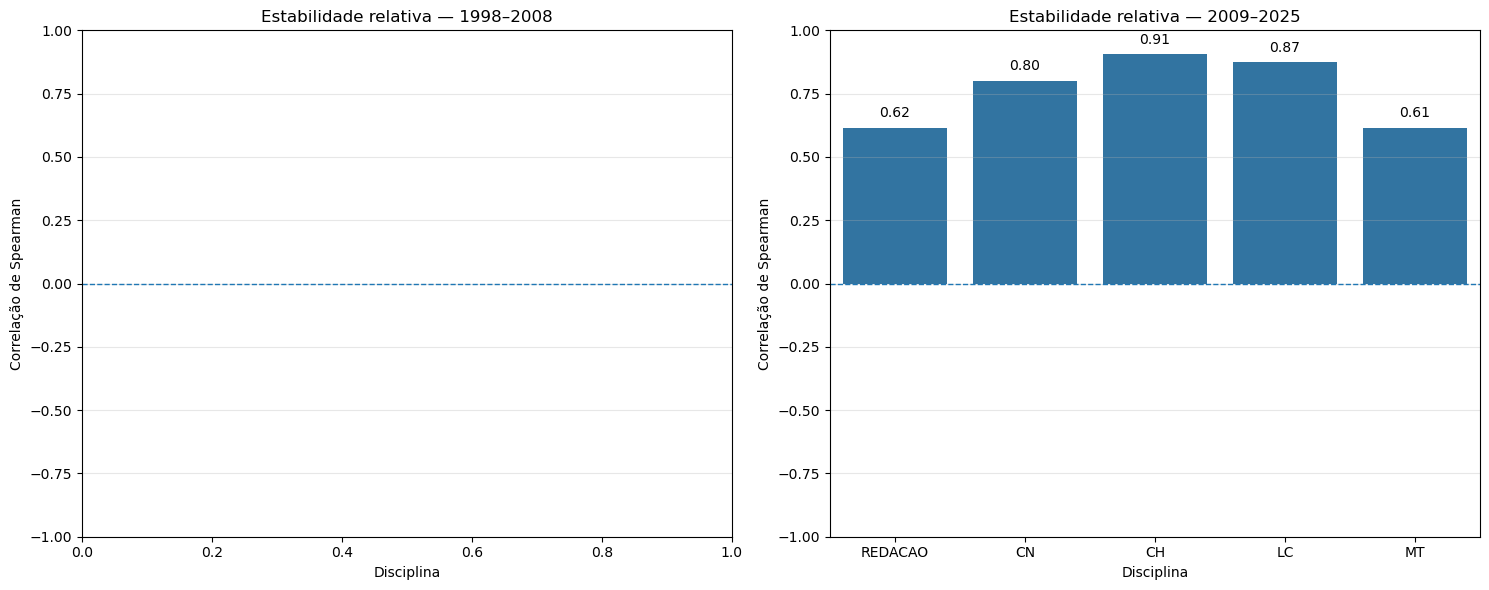

In [14]:
# ============================================================
# 8.1. VISUALIZAÇÃO — ESTABILIDADE RELATIVA
# ============================================================

fig, axes = plt.subplots(1,2,figsize=(15, 6))

for ax, periodo_id in zip(axes,
    ["1998_2008",
     "2009_2025"]):

    dados = estabilidade_posicao_periodizada[
        estabilidade_posicao_periodizada["periodo"]
        == periodo_id
    ].copy()

    sns.barplot(
        data=dados,
        x="disciplina",
        y="spearman",
        ax=ax,
    )

    ax.axhline(
        0,
        linestyle="--",
        linewidth=1,
    )

    ax.set_ylim(-1, 1)

    ax.set_title(
        f"Estabilidade relativa — "
        f"{PERIODOS[periodo_id]['rotulo']}"
    )

    ax.set_xlabel("Disciplina")
    ax.set_ylabel("Correlação de Spearman")

    ax.grid(
        axis="y",
        alpha=0.3,
    )

    for barra in ax.patches:

        altura = barra.get_height()

        ax.text(
            barra.get_x()
            + barra.get_width() / 2,
            altura + (
                0.03
                if altura >= 0
                else -0.03
            ),
            f"{altura:.2f}",
            ha="center",
            va=(
                "bottom"
                if altura >= 0
                else "top"
            ),
        )

plt.tight_layout()
plt.show()

## 9. Ranking municipal anual — Top 5 / Bottom 5

In [15]:
ranking_antigo = construir_ranking_periodo(painel,PERIODO_ANTIGO,DISCIPLINAS_ANTIGO)
ranking_novo = construir_ranking_periodo(painel,PERIODO_NOVO,DISCIPLINAS_NOVO)
ranking_anual_periodizado = pd.concat([ranking_antigo,ranking_novo],ignore_index=True)

display(ranking_anual_periodizado.head(10))

,periodo,ano,disciplina,versao_redacao,faixa_ranking,posicao,CO_MUNICIPIO_TERRITORIO,NO_MUNICIPIO_TERRITORIO,media,n_validos
0,1998_2008,1998,OBJETIVA,None,BOTTOM 5,1,2210706,SIMOES,0.000000,2.0
1,1998_2008,1998,OBJETIVA,None,BOTTOM 5,2,2205953,MARCOLANDIA,0.000000,1.0
2,1998_2008,1998,OBJETIVA,None,BOTTOM 5,3,2211001,TERESINA,32.782653,98.0
3,1998_2008,1998,OBJETIVA,None,BOTTOM 5,4,2208007,PICOS,41.300000,1.0
4,1998_2008,1998,OBJETIVA,None,BOTTOM 5,5,2210409,SAO MIGUEL DO TAPUIO,50.800000,1.0
5,1998_2008,1998,OBJETIVA,None,TOP 5,1,2210409,SAO MIGUEL DO TAPUIO,50.800000,1.0
6,1998_2008,1998,OBJETIVA,None,TOP 5,2,2208007,PICOS,41.300000,1.0
7,1998_2008,1998,OBJETIVA,None,TOP 5,3,2211001,TERESINA,32.782653,98.0
8,1998_2008,1998,OBJETIVA,None,TOP 5,4,2210706,SIMOES,0.000000,2.0
9,1998_2008,1998,OBJETIVA,None,TOP 5,5,2205953,MARCOLANDIA,0.000000,1.0


## 10. Frequência e recorrência nos extremos do ranking

In [16]:
# ============================================================
# 10. MUNICÍPIOS MAIS RECORRENTES
# ============================================================
frequencia_ranking_periodizada,rec_top,rec_bot = freq_rank_period(ranking_anual_periodizado)

display(frequencia_ranking_periodizada.head(5))

display(rec_top[["periodo","disciplina","NO_MUNICIPIO_TERRITORIO","n_aparicoes","anos"]].head(5))
display(rec_bot[["periodo","disciplina","NO_MUNICIPIO_TERRITORIO","n_aparicoes","anos"]].head(5))

,periodo,disciplina,faixa_ranking,CO_MUNICIPIO_TERRITORIO,NO_MUNICIPIO_TERRITORIO,n_aparicoes,anos
0,1998_2008,OBJETIVA,BOTTOM 5,2200053,ACAUA,2,"2004, 2005"
1,1998_2008,OBJETIVA,BOTTOM 5,2201507,BATALHA,2,"2000, 2008"
2,1998_2008,OBJETIVA,BOTTOM 5,2202109,CAMPINAS DO PIAUI,2,"2004, 2005"
3,1998_2008,OBJETIVA,BOTTOM 5,2202251,CANAVIEIRA,2,"2005, 2006"
4,1998_2008,OBJETIVA,BOTTOM 5,2202505,CARACOL,2,"2001, 2002"


,periodo,disciplina,NO_MUNICIPIO_TERRITORIO,n_aparicoes,anos
46,1998_2008,OBJETIVA,TERESINA,5,"1998, 1999, 2000, 2007, 2008"
47,1998_2008,OBJETIVA,FLORIANO,3,"2002, 2005, 2008"
48,1998_2008,OBJETIVA,ALTOS,2,"1999, 2000"
49,1998_2008,OBJETIVA,CAMPO MAIOR,2,"2007, 2008"
50,1998_2008,OBJETIVA,COLONIA DO PIAUI,2,"2003, 2006"


,periodo,disciplina,NO_MUNICIPIO_TERRITORIO,n_aparicoes,anos
0,1998_2008,OBJETIVA,ACAUA,2,"2004, 2005"
1,1998_2008,OBJETIVA,BATALHA,2,"2000, 2008"
2,1998_2008,OBJETIVA,CAMPINAS DO PIAUI,2,"2004, 2005"
3,1998_2008,OBJETIVA,CANAVIEIRA,2,"2005, 2006"
4,1998_2008,OBJETIVA,CARACOL,2,"2001, 2002"


### 10.1 Visualização da recorrência

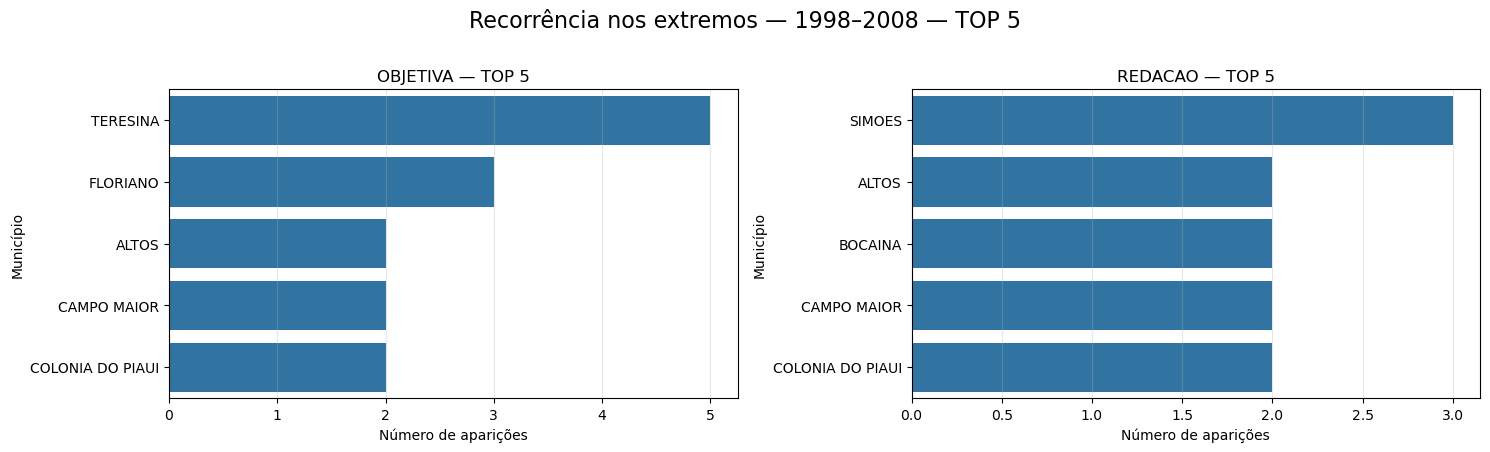

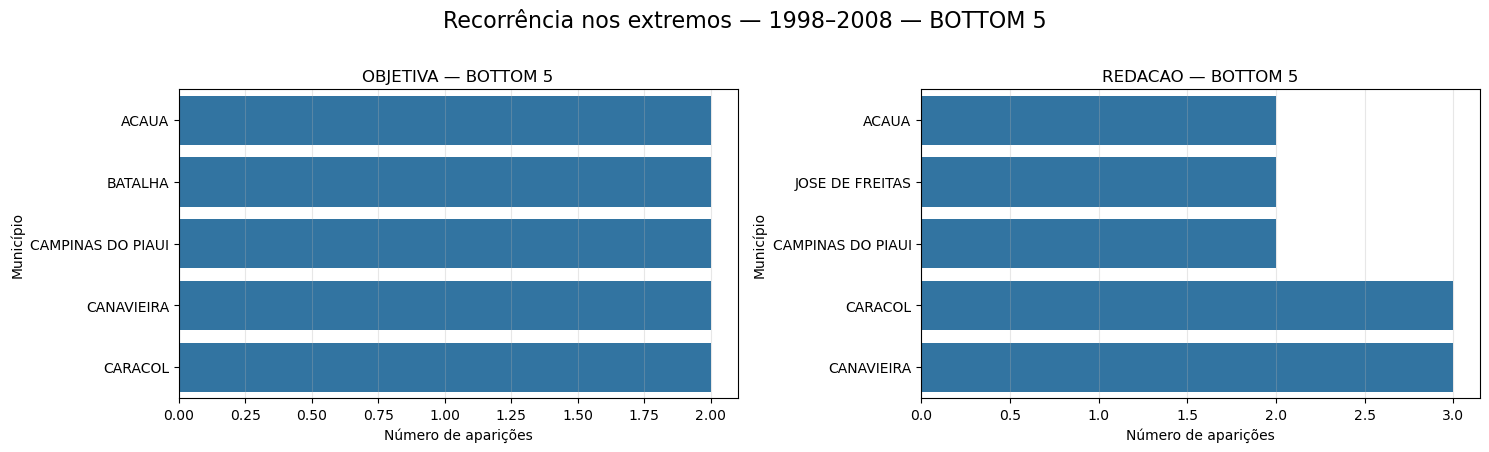

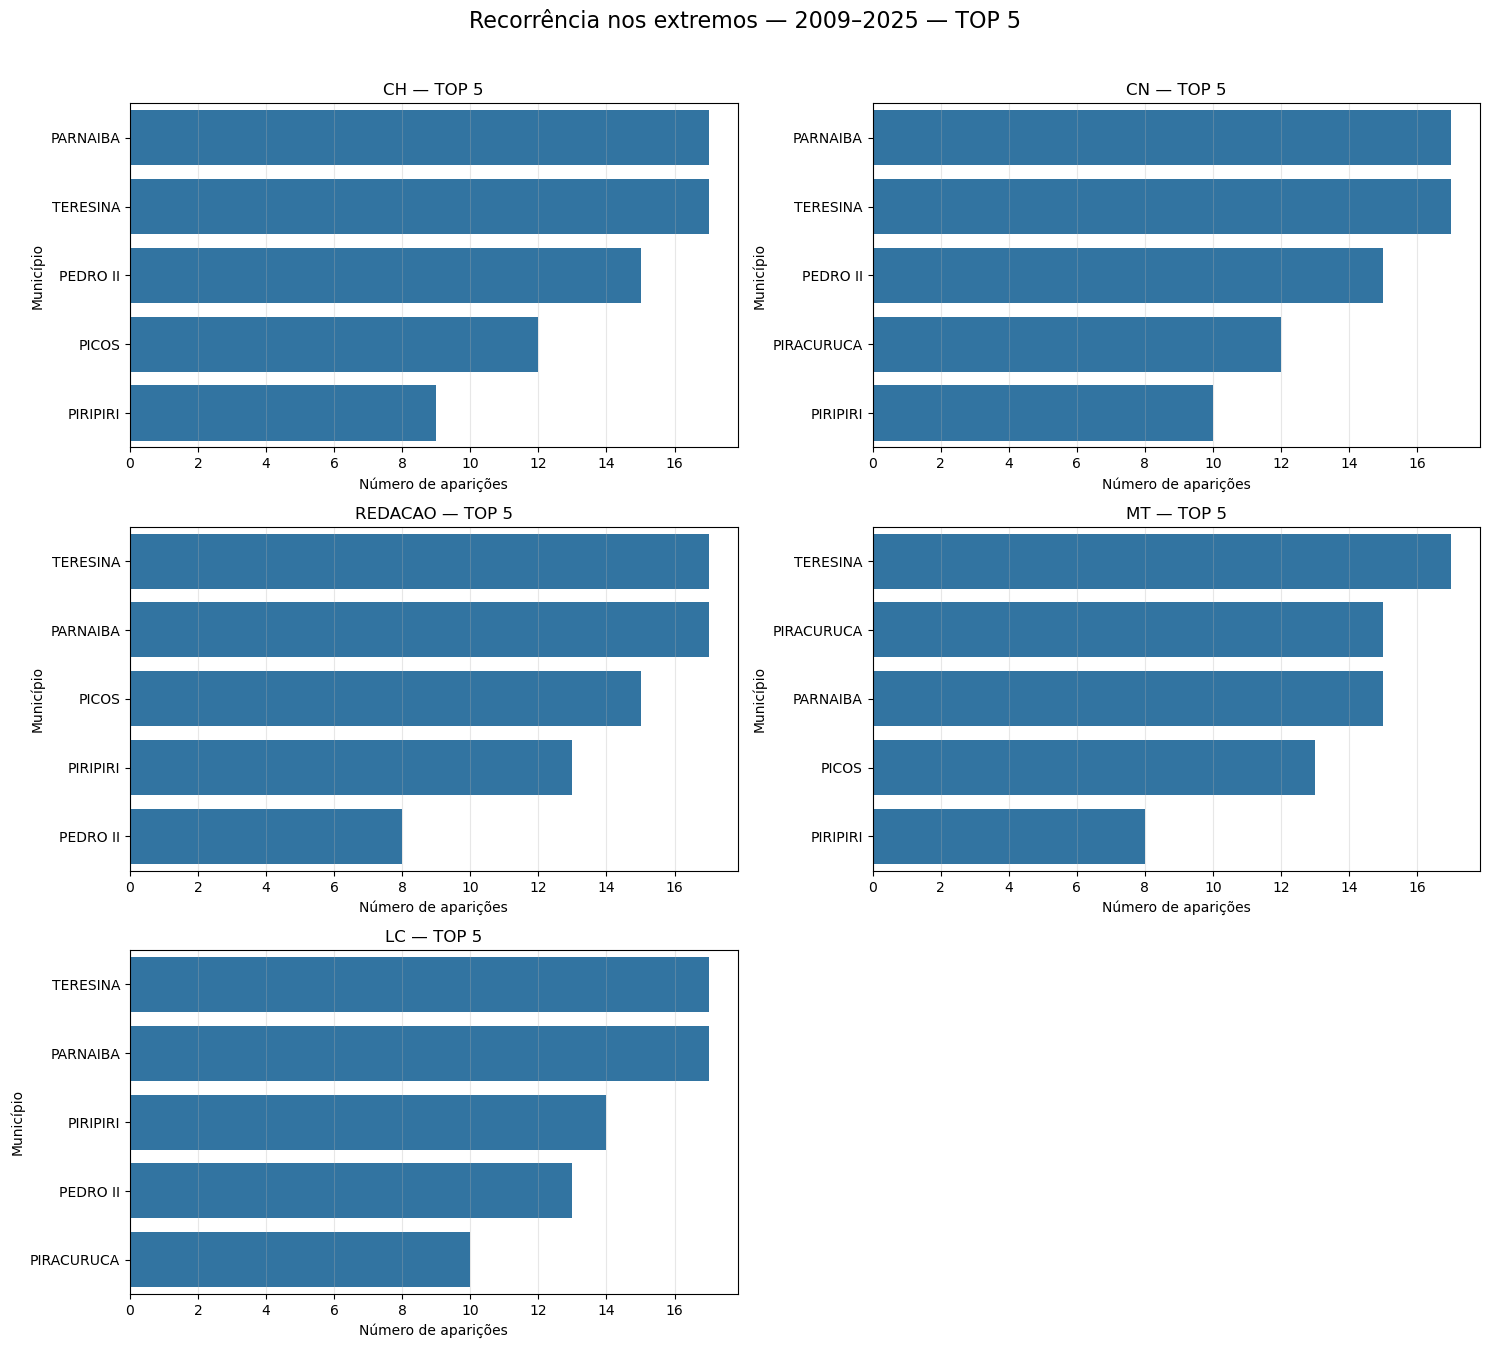

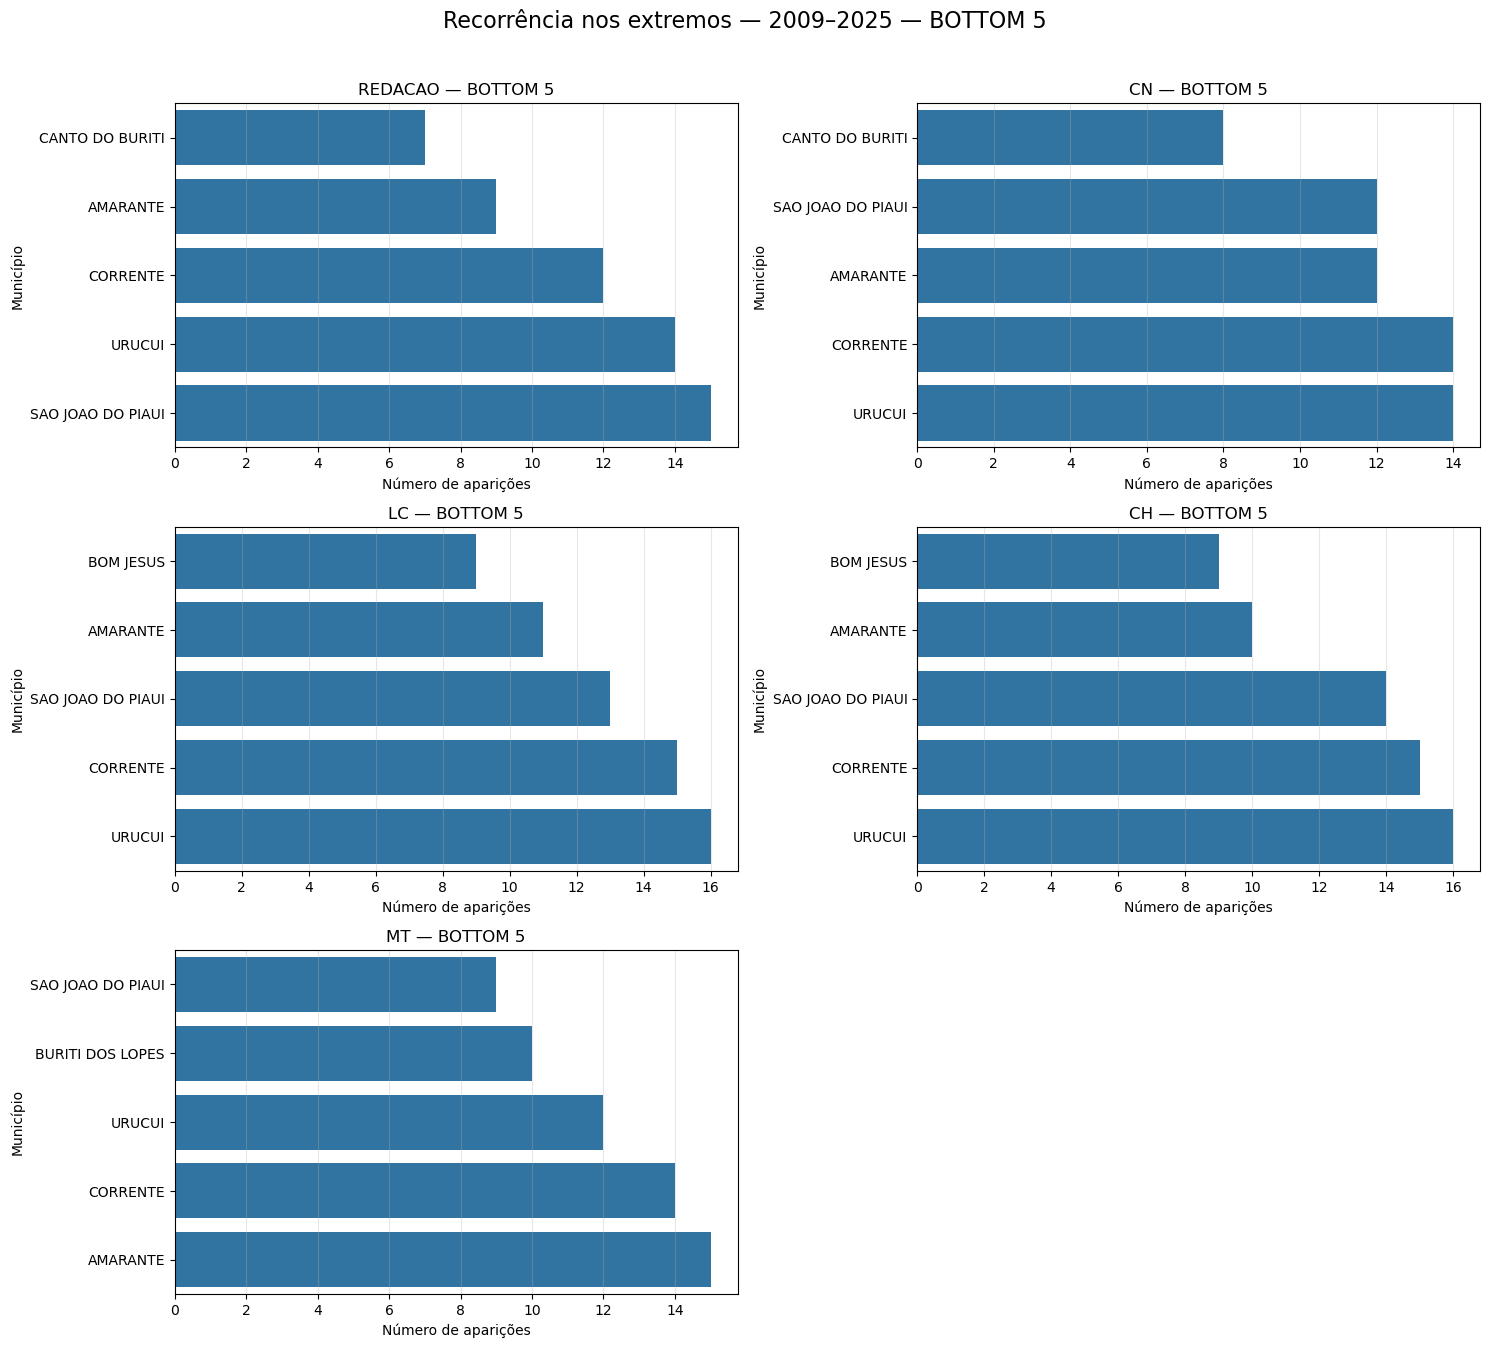

In [17]:
# ============================================================
# 10.1 VISUALIZAÇÃO — RECORRÊNCIA
# ============================================================
from utils.eda import plotar_recorrencia

for periodo_id in ["1998_2008","2009_2025"]:
    plotar_recorrencia(rec_top,periodo_id,"TOP 5")
    plotar_recorrencia(rec_bot,periodo_id,"BOTTOM 5")

## 11. Diferença de desempenho — privada × pública

In [18]:
# ============================================================
# 11. GAP PRIVADA × PÚBLICA — PERIODIZADO
# ============================================================
from utils.eda import gap_period

resultado_gap_periodizado=gap_period(grupo)
display(resultado_gap_periodizado.round(3).head(5))

,periodo,ano,disciplina,NAO_INFORMADA_x,media_privada,media_publica,NAO_INFORMADA_y,n_validos_privada,n_validos_publica,n_nao_informada,gap_privada_publica
0,1998_2008,2001,OBJETIVA,NaN,40.161,23.867,NaN,979.0,5876.0,0.0,16.294
1,1998_2008,2001,REDACAO,NaN,50.066,32.804,NaN,979.0,5876.0,0.0,17.263
2,1998_2008,2002,OBJETIVA,NaN,33.410,17.779,NaN,2573.0,13266.0,0.0,15.631
3,1998_2008,2002,REDACAO,NaN,50.779,30.506,NaN,2573.0,13266.0,0.0,20.273
4,1998_2008,2003,OBJETIVA,NaN,42.765,20.585,NaN,2636.0,14957.0,0.0,22.181


### 11.1 Visualização do gap

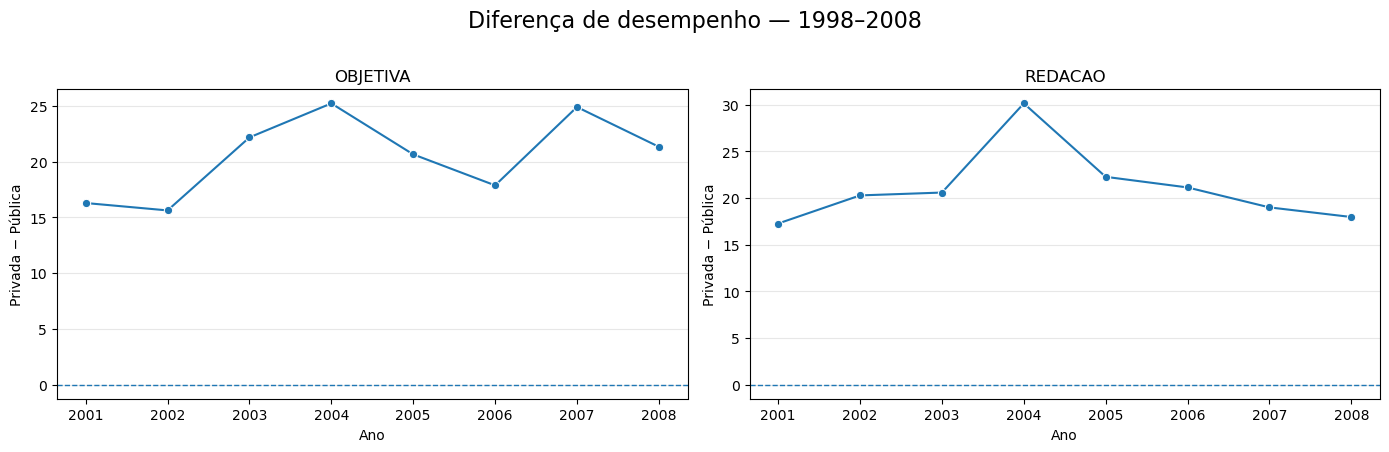

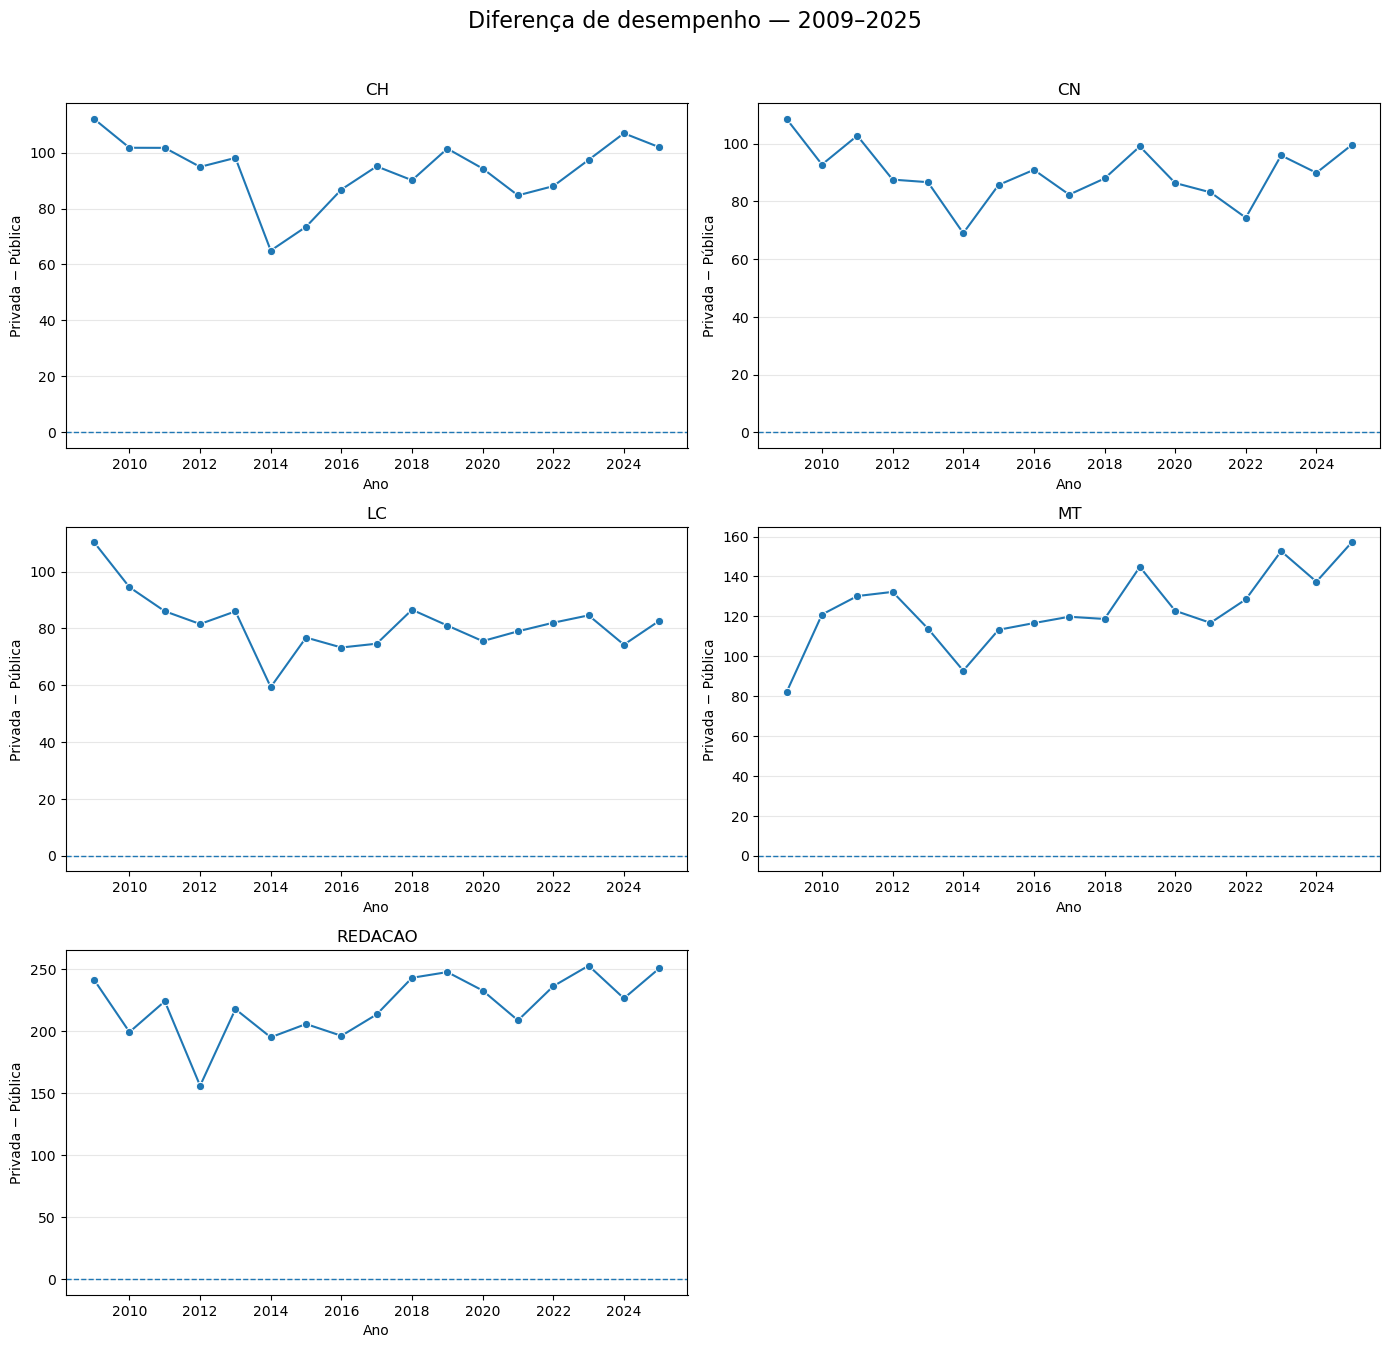

In [19]:
# ============================================================
# 11.1. VISUALIZAÇÃO — GAP PRIVADA × PÚBLICA
# ============================================================
from utils.eda import plotar_gap_rede


plotar_gap_rede(resultado_gap_periodizado,"1998_2008")

plotar_gap_rede(resultado_gap_periodizado,"2009_2025",)

## 12. Síntese longitudinal por período

In [20]:
# ============================================================
# 12. SÍNTESE LONGITUDINAL
# ============================================================

sintese_longitudinal_periodizada = (tendencia_estadual_periodizada.copy())

sintese_longitudinal_periodizada["direcao"] = np.select(
    [sintese_longitudinal_periodizada["slope_pontos_ano"] > 0,sintese_longitudinal_periodizada["slope_pontos_ano"] < 0],
    ["positiva","negativa"],default="nula")

display(sintese_longitudinal_periodizada.round(3))

,periodo,periodo_rotulo,disciplina,versao_redacao,n_anos,media_inicial,media_final,variacao_primeiro_ultimo,slope_pontos_ano,erro_padrao_slope,r2,p_valor,direcao
0,1998_2008,1998–2008,OBJETIVA,NaN,11,32.085,27.632,-4.453,-1.481,1.000,0.196,0.173,negativa
1,1998_2008,1998–2008,REDACAO,antiga,11,36.019,44.297,8.278,-0.702,1.033,0.049,0.514,negativa
2,2009_2025,2009–2025,REDACAO,nova,17,408.428,571.616,163.188,16.175,2.739,0.699,0.000,positiva
3,2009_2025,2009–2025,CN,NaN,17,480.898,482.841,1.944,1.069,0.570,0.190,0.080,positiva
4,2009_2025,2009–2025,CH,NaN,17,490.928,487.763,-3.165,-0.778,1.142,0.030,0.506,negativa
5,2009_2025,2009–2025,LC,NaN,17,482.503,510.835,28.332,1.261,0.494,0.303,0.022,positiva
6,2009_2025,2009–2025,MT,NaN,17,473.346,491.416,18.069,2.796,0.820,0.436,0.004,positiva
